In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

**Read In Integrated Assistance Demographics**

In [2]:
integrated_assistance_demographics = pd.read_csv("Assistance_Demographics_Master.csv")
integrated_assistance_demographics.head(5)

,Zip Code,Month Year,Calfresh_Dollars,Calfresh_Meal_Cost,Calfresh_Meals,Calfresh_Outlier,LIHEAP_Enrollment_Count,LIHEAP_Outlier,FSD_Pounds,SDFB_Pounds,...,Single_Father_Households_With_Own_Children_Under18,Single_Mother_Households_With_Own_Children_Under18,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,Median_Monthly_Owner_Cost_No_Mortgage,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct
0,91901,2018-01,NaN,NaN,NaN,NaN,NaN,NaN,7884.0,0.0,...,137.0,354.0,1465.0,2736.0,709.0,4220.0,11115.0,3223.0,8.5,4.2
1,91901,2018-02,NaN,NaN,NaN,NaN,NaN,NaN,10558.0,0.0,...,137.0,354.0,1465.0,2736.0,709.0,4220.0,11115.0,3223.0,8.5,4.2
2,91901,2018-03,NaN,NaN,NaN,NaN,NaN,NaN,10642.0,0.0,...,137.0,354.0,1465.0,2736.0,709.0,4220.0,11115.0,3223.0,8.5,4.2
3,91901,2018-04,NaN,NaN,NaN,NaN,NaN,NaN,12192.0,0.0,...,137.0,354.0,1465.0,2736.0,709.0,4220.0,11115.0,3223.0,8.5,4.2
4,91901,2018-05,NaN,NaN,NaN,NaN,NaN,NaN,10370.0,0.0,...,137.0,354.0,1465.0,2736.0,709.0,4220.0,11115.0,3223.0,8.5,4.2


**Return San Diego County Zip Code Boundary Shapefile or GeoJSON**

In [3]:
import geopandas as gpd

url = ("https://geo.sandag.org/server/rest/services/Hosted/Zipcodes/FeatureServer/0/query"
       "?where=1%3D1&outFields=*&outSR=4326&f=geojson")
zips_gdf = gpd.read_file(url)
zips_gdf.to_file("SD_Zipcodes.geojson", driver="GeoJSON")   # save a local copy
print(zips_gdf.shape, zips_gdf.columns.tolist())

(122, 7) ['zip', 'globalid', 'community', 'SHAPE__Length', 'objectid', 'SHAPE__Area', 'geometry']


In [4]:
zips_gdf.head(5)

,zip,globalid,community,SHAPE__Length,objectid,SHAPE__Area,geometry
0,92054,{9C7FE07C-98C6-46AB-976A-F8BA87B98F8A},Oceanside,90310.877622,1,2.060265e+08,"POLYGON ((-117.33208 33.21772, -117.33201 33.2..."
1,92024,{0D2C674B-7425-48CE-AD09-8EF037AD7107},Encinitas,157599.482632,2,5.068459e+08,"POLYGON ((-117.20926 33.09568, -117.20939 33.0..."
2,92106,{AA93B919-7FFB-4720-9F56-19B8FBE0515A},San Diego,91488.102750,3,2.273840e+08,"POLYGON ((-117.21852 32.75173, -117.21973 32.7..."
3,92154,{526D2022-5D98-4085-857E-10150BD994BB},San Diego,270477.500159,4,1.207194e+09,"POLYGON ((-117.09876 32.60902, -117.09873 32.6..."
4,92536,{58BC8C56-8CEB-4C66-AC8F-4AC02068CFA8},Aguanga,206176.033197,5,1.389177e+09,"POLYGON ((-116.69357 33.42742, -116.69989 33.4..."


**Merge Integrated Demographics dataset and San Diego County Zip Code**

In [5]:
GEO_ZIP = "zip"
DATA_ZIP = "Zip Code"

In [6]:
zips_gdf["Zip_Code"] = zips_gdf[GEO_ZIP].astype(str).str.zfill(5)
integrated_assistance_demographics["Zip_Code"] = integrated_assistance_demographics[DATA_ZIP].astype(str).str.split(".").str[0].str.zfill(5)

**Drop Zip Code Column in integrated assistance dempgraphics**

In [7]:
integrated_assistance_demographics = integrated_assistance_demographics.drop(columns="Zip Code")

**Merge each zips polygon into one shape, keeping the first community name**
- fit duplication zip code issue, set zip code to 92058 to oceanside

In [8]:
zips_clean = (zips_gdf[["Zip_Code", "community", "geometry"]]
              .dissolve(by="Zip_Code", aggfunc="first")
              .reset_index()
              .rename(columns={"community": "City"}))

zips_clean.loc[zips_clean["Zip_Code"] == "92058", "City"] = "Oceanside"

assert zips_clean["Zip_Code"].is_unique

**Outer Merge So Nothing is silentry dropped from either side**

In [9]:
merged = zips_clean.merge(integrated_assistance_demographics, on="Zip_Code", how="outer",
                          validate="one_to_many", indicator=True)

**Check to see if there are any data issues**

In [10]:
data_zips = integrated_assistance_demographics["Zip_Code"].unique()
missing_boundary = sorted(merged.loc[merged["_merge"] == "right_only", "Zip_Code"].unique())
no_data = sorted(merged.loc[merged["_merge"] == "left_only",  "Zip_Code"].unique())

In [11]:
print(f"Zip codes in data: {len(data_zips)}")
print(f"Matched to a boundary: {len(data_zips) - len(missing_boundary)}")
print(f"In data but missing a boundary ({len(missing_boundary)}):", missing_boundary)
print(f"Boundary with no assistance data ({len(no_data)}):", no_data)

Zip codes in data: 165
Matched to a boundary: 103
In data but missing a boundary (62): ['91903', '91908', '91909', '91912', '91921', '91933', '91943', '91944', '91946', '91951', '91976', '91979', '92013', '92018', '92022', '92023', '92030', '92033', '92038', '92039', '92046', '92049', '92051', '92052', '92068', '92072', '92074', '92079', '92085', '92088', '92092', '92112', '92137', '92138', '92142', '92143', '92149', '92150', '92153', '92159', '92160', '92163', '92165', '92166', '92167', '92168', '92169', '92170', '92171', '92172', '92174', '92175', '92176', '92177', '92178', '92186', '92191', '92192', '92193', '92195', '92196', '92198']
Boundary with no assistance data (10): ['91948', '92096', '92134', '92135', '92155', '92161', '92182', '92259', '92536', '92672']


**Row from both groups**
- return the isues with data but no boundary as well as boundary but no data

In [12]:
problem = merged[merged["_merge"].isin(["right_only", "left_only"])].copy()
problem["Issue"] = problem["_merge"].map({
    "right_only": "Data but no boundary",
    "left_only":  "Boundary but no data",
})

In [13]:
problem

,Zip_Code,geometry,City,Month Year,Calfresh_Dollars,Calfresh_Meal_Cost,Calfresh_Meals,Calfresh_Outlier,LIHEAP_Enrollment_Count,LIHEAP_Outlier,...,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,Median_Monthly_Owner_Cost_No_Mortgage,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct,_merge,Issue
184,91903,None,NaN,2020-01,8938.0,3.473000,2573.567271,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,right_only,Data but no boundary
185,91903,None,NaN,2020-02,7423.0,3.481491,2132.132391,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,right_only,Data but no boundary
186,91903,None,NaN,2020-03,10288.0,3.494707,2943.880534,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,right_only,Data but no boundary
187,91903,None,NaN,2020-04,17836.0,3.511883,5078.757305,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,right_only,Data but no boundary
188,91903,None,NaN,2020-05,18935.0,3.532253,5360.601528,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,right_only,Data but no boundary
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13601,92198,None,NaN,2025-07,9229.0,4.725154,1953.163959,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,right_only,Data but no boundary
13602,92198,None,NaN,2025-08,10415.0,4.657416,2236.218552,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,right_only,Data but no boundary
13603,92259,"POLYGON ((-116.10323 32.87887, -116.10573 32.8...",Ocotillo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only,Boundary but no data
13604,92536,"POLYGON ((-116.69357 33.42742, -116.69989 33.4...",Aguanga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only,Boundary but no data


In [14]:
summary = (problem.groupby(["Zip_Code", "Issue"], as_index=False)
           .agg(City=("City", "first"),
                Months=("Month Year", "nunique"),
                CalFresh_Dollars=("Calfresh_Dollars", "sum"),
                LIHEAP_Enrollment=("LIHEAP_Enrollment_Count", "sum"),
                FSD_Pounds=("FSD_Pounds", "sum"))
           .sort_values(["Issue", "CalFresh_Dollars"], ascending=[True, False])
           .reset_index(drop=True))

pd.set_option("display.max_rows", 100)
display(summary)

,Zip_Code,Issue,City,Months,CalFresh_Dollars,LIHEAP_Enrollment,FSD_Pounds
0,91948,Boundary but no data,Mount Laguna,0,0.00,0.0,0.0
1,92096,Boundary but no data,San Marcos,0,0.00,0.0,0.0
2,92134,Boundary but no data,San Diego,0,0.00,0.0,0.0
3,92135,Boundary but no data,Coronado,0,0.00,0.0,0.0
4,92155,Boundary but no data,Coronado,0,0.00,0.0,0.0
5,92161,Boundary but no data,San Diego,0,0.00,0.0,0.0
6,92182,Boundary but no data,San Diego,0,0.00,0.0,0.0
7,92259,Boundary but no data,Ocotillo,0,0.00,0.0,0.0
8,92536,Boundary but no data,Aguanga,0,0.00,0.0,0.0
9,92672,Boundary but no data,San Clemente,0,0.00,0.0,0.0


**Remove the records where the zip code does not belong in san diego**

In [15]:
OUT_OF_COUNTY = ["San Clemente", "Aguanga", "Ocotillo"]

# See what's being removed
print(merged.loc[merged["City"].isin(OUT_OF_COUNTY), ["Zip_Code", "City"]].drop_duplicates())

# Keep only San Diego County records
merged = merged[~merged["City"].isin(OUT_OF_COUNTY)].reset_index(drop=True)

# Confirm they're gone
print(merged["City"].isin(OUT_OF_COUNTY).sum(), "out-of-county rows remaining")

      Zip_Code          City
13603    92259      Ocotillo
13604    92536       Aguanga
13605    92672  San Clemente
0 out-of-county rows remaining


**Assign City Classification to zip codes without a city**

In [16]:
#define the zip code and its assignment to the approaite city 

po_box_cities = {
    "91903": "Alpine",        "91908": "Bonita",         "91909": "Chula Vista",
    "91912": "Chula Vista",   "91921": "Chula Vista",    "91933": "Imperial Beach",
    "91943": "La Mesa",       "91944": "La Mesa",        "91946": "Lemon Grove",
    "91951": "National City", "91976": "Spring Valley",  "91979": "Spring Valley",
    "92013": "Carlsbad",      "92018": "Carlsbad",       "92022": "El Cajon",
    "92023": "Encinitas",     "92030": "Escondido",      "92033": "Escondido",
    "92038": "La Jolla",      "92039": "La Jolla",       "92046": "Escondido",
    "92049": "Oceanside",     "92051": "Oceanside",      "92052": "Oceanside",
    "92068": "San Luis Rey",  "92072": "Santee",         "92074": "Poway",
    "92079": "San Marcos",    "92085": "Vista",          "92088": "Fallbrook",
    "92092": "La Jolla",      "92112": "San Diego",      "92137": "San Diego",
    "92138": "San Diego",     "92142": "San Diego",      "92143": "San Ysidro",
    "92149": "San Diego",     "92150": "San Diego",      "92153": "San Diego",
    "92159": "San Diego",     "92160": "San Diego",      "92163": "San Diego",
    "92165": "San Diego",     "92166": "San Diego",      "92167": "San Diego",
    "92168": "San Diego",     "92169": "San Diego",      "92170": "San Diego",
    "92171": "San Diego",     "92172": "San Diego",      "92174": "San Diego",
    "92175": "San Diego",     "92176": "San Diego",      "92177": "San Diego",
    "92178": "Coronado",      "92186": "San Diego",      "92191": "San Diego",
    "92192": "San Diego",     "92193": "San Diego",      "92195": "San Diego",
    "92196": "San Diego",     "92198": "San Diego"}

In [17]:
merged["City"] = merged["City"].fillna(merged["Zip_Code"].map(po_box_cities))
summary["City"] = summary["City"].fillna(summary["Zip_Code"].map(po_box_cities))

In [18]:
print(merged["City"].isna().sum(), "rows still missing a city")

0 rows still missing a city


**Check with rows do not have a geometry classification**

In [19]:
merged["Has_Geometry"] = merged.geometry.notna().astype(int)

full_table = merged.drop(columns="geometry")
full_table.to_csv("Assistance_Spatial_FUll.csv", index=False)

**Create a spatial dataset with mapped rows only**

In [20]:
spatial = merged[merged["Has_Geometry"] == 1].copy()
spatial.to_file("Assistance_Spatial.geojson", driver="GeoJSON")

**Report how much is excluded from the maps**

In [21]:
for col in ["Calfresh_Dollars", "LIHEAP_Enrollment_Count", "FSD_Pounds"]:
    excluded = 1 - spatial[col].sum() / merged[col].sum()
    print(f"{col}: {excluded:.1%} not shown on maps")

Calfresh_Dollars: 7.1% not shown on maps
LIHEAP_Enrollment_Count: 1.2% not shown on maps
FSD_Pounds: -0.0% not shown on maps


**Develop a dataframe with one row per zip code**

In [22]:
START, END = "2023-01", "2023-07"
window = merged[(merged["Month Year"] >= START) & (merged["Month Year"] <= END)]

zip_df = (window.groupby("Zip_Code")
         .agg(City=("City", "first"),
             CalFresh_Monthly=("Calfresh_Dollars", "mean"),
             LIHEAP_Monthly=("LIHEAP_Enrollment_Count", "mean"),
             FSD_Monthly=("FSD_Pounds", "mean"),
             Pop_U18=("Population_Under_18", "first"),
             Pop_18_64=("Population_18_to_64", "first"),
             Pop_65=("Population_65_Plus", "first"),
             Poverty_Rate_Pct=("Poverty_Rate_Pct", "first"),
             Unemployment_Rate_Pct=("Unemployment_Rate_Pct", "first"),
             Median_Gross_Rent=("Median_Gross_Rent", "first"),
             Single_Mothers=("Single_Mother_Households_With_Own_Children_Under18", "first")).reset_index())

**Fix Issue with Zip Code City Mapping**

In [23]:
zip_city_fix = {
    "91948": "Mount Laguna",
    "92096": "San Marcos",
    "92134": "San Diego",
    "92135": "San Diego",
    "92155": "San Diego",
    "92161": "San Diego",
    "92182": "San Diego",
}

zip_df["City"] = zip_df["Zip_Code"].map(zip_city_fix).fillna(zip_df["City"])

In [24]:
zip_df["Population"] = zip_df[["Pop_U18", "Pop_18_64", "Pop_65"]].sum(axis=1, min_count=1)
zip_df.head(5)

,Zip_Code,City,CalFresh_Monthly,LIHEAP_Monthly,FSD_Monthly,Pop_U18,Pop_18_64,Pop_65,Poverty_Rate_Pct,Unemployment_Rate_Pct,Median_Gross_Rent,Single_Mothers,Population
0,91901,Alpine,276465.941429,1.500000,25700.696429,3840.0,11191.0,3269.0,10.2,5.4,2064.0,177.0,18300.0
1,91902,Bonita,300307.668571,2.200000,3946.000000,3260.0,9799.0,4386.0,5.9,6.2,2252.0,134.0,17445.0
2,91903,Alpine,23576.575714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,91905,Boulevard,104046.290000,1.333333,5474.857143,234.0,828.0,404.0,20.9,0.0,1077.0,9.0,1466.0
4,91906,Campo,172377.508571,1.000000,18646.791286,760.0,1988.0,627.0,15.1,3.0,1863.0,119.0,3375.0


In [25]:
count_cols = ["Pop_U18", "Pop_18_64", "Pop_65", "Population", "Single_Mothers"]
zip_df[count_cols] = zip_df[count_cols].astype("float64")

In [26]:
zip_df.head(5)

,Zip_Code,City,CalFresh_Monthly,LIHEAP_Monthly,FSD_Monthly,Pop_U18,Pop_18_64,Pop_65,Poverty_Rate_Pct,Unemployment_Rate_Pct,Median_Gross_Rent,Single_Mothers,Population
0,91901,Alpine,276465.941429,1.500000,25700.696429,3840.0,11191.0,3269.0,10.2,5.4,2064.0,177.0,18300.0
1,91902,Bonita,300307.668571,2.200000,3946.000000,3260.0,9799.0,4386.0,5.9,6.2,2252.0,134.0,17445.0
2,91903,Alpine,23576.575714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,91905,Boulevard,104046.290000,1.333333,5474.857143,234.0,828.0,404.0,20.9,0.0,1077.0,9.0,1466.0
4,91906,Campo,172377.508571,1.000000,18646.791286,760.0,1988.0,627.0,15.1,3.0,1863.0,119.0,3375.0


**Set Per Capita Rates**

In [27]:
#filter for record where the population has 500 people or more
pop = zip_df["Population"].where(zip_df["Population"] >= 500)

#determine liheap enrollments per 100 residents per month 
zip_df["LIHEAP_per_1k"] = zip_df["LIHEAP_Monthly"] / pop * 1000

#determine calfresh dollars per resident per month 
zip_df["CalFresh_per_capita"] = zip_df["CalFresh_Monthly"] / pop

#determine foodbank pounds of food donated per resdient per month 
zip_df["FSD_lbs_per_capita"] = zip_df["FSD_Monthly"] / pop

#determine number of single mother households per 1000 residents 
zip_df["Single_Mothers_per_1k"] = zip_df["Single_Mothers"] / pop * 1000

In [28]:
zip_df.head(5)

,Zip_Code,City,CalFresh_Monthly,LIHEAP_Monthly,FSD_Monthly,Pop_U18,Pop_18_64,Pop_65,Poverty_Rate_Pct,Unemployment_Rate_Pct,Median_Gross_Rent,Single_Mothers,Population,LIHEAP_per_1k,CalFresh_per_capita,FSD_lbs_per_capita,Single_Mothers_per_1k
0,91901,Alpine,276465.941429,1.500000,25700.696429,3840.0,11191.0,3269.0,10.2,5.4,2064.0,177.0,18300.0,0.081967,15.107428,1.404410,9.672131
1,91902,Bonita,300307.668571,2.200000,3946.000000,3260.0,9799.0,4386.0,5.9,6.2,2252.0,134.0,17445.0,0.126111,17.214541,0.226197,7.681284
2,91903,Alpine,23576.575714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,91905,Boulevard,104046.290000,1.333333,5474.857143,234.0,828.0,404.0,20.9,0.0,1077.0,9.0,1466.0,0.909504,70.972913,3.734555,6.139154
4,91906,Campo,172377.508571,1.000000,18646.791286,760.0,1988.0,627.0,15.1,3.0,1863.0,119.0,3375.0,0.296296,51.074817,5.524975,35.259259


**Combine the assistance index**
- this builds the combined index, a single 0-100 score that summarize the assistance receive3d from all three programs for each zip code

In [29]:
rate_cols = ["LIHEAP_per_1k", "CalFresh_per_capita", "FSD_lbs_per_capita"]
pct = zip_df[rate_cols].rank(pct=True) * 100
zip_df["Programs_Reporting"] = pct.notna().sum(axis=1)
zip_df["Assistance_Burden_Index"] = pct.mean(axis=1).where(zip_df["Programs_Reporting"] >= 2)

In [30]:
zip_df.head(5)

,Zip_Code,City,CalFresh_Monthly,LIHEAP_Monthly,FSD_Monthly,Pop_U18,Pop_18_64,Pop_65,Poverty_Rate_Pct,Unemployment_Rate_Pct,Median_Gross_Rent,Single_Mothers,Population,LIHEAP_per_1k,CalFresh_per_capita,FSD_lbs_per_capita,Single_Mothers_per_1k,Programs_Reporting,Assistance_Burden_Index
0,91901,Alpine,276465.941429,1.500000,25700.696429,3840.0,11191.0,3269.0,10.2,5.4,2064.0,177.0,18300.0,0.081967,15.107428,1.404410,9.672131,3,41.357945
1,91902,Bonita,300307.668571,2.200000,3946.000000,3260.0,9799.0,4386.0,5.9,6.2,2252.0,134.0,17445.0,0.126111,17.214541,0.226197,7.681284,3,34.858748
2,91903,Alpine,23576.575714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,91905,Boulevard,104046.290000,1.333333,5474.857143,234.0,828.0,404.0,20.9,0.0,1077.0,9.0,1466.0,0.909504,70.972913,3.734555,6.139154,3,94.563861
4,91906,Campo,172377.508571,1.000000,18646.791286,760.0,1988.0,627.0,15.1,3.0,1863.0,119.0,3375.0,0.296296,51.074817,5.524975,35.259259,3,85.582282


**Attach the Boundaries**

In [31]:
import mapclassify

In [32]:
import geopandas as gpd

shapes = merged[merged.geometry.notna()].drop_duplicates("Zip_Code")[["Zip_Code", "geometry"]]
gdf = gpd.GeoDataFrame(shapes.merge(zip_df, on="Zip_Code", how="left"),
                      geometry="geometry", crs=merged.crs).to_crs(epsg=26911)

In [33]:
# Fill cities for boundary-only zips (not in zip_df, so City is blank here)
gdf["City"] = gdf["Zip_Code"].map(zip_city_fix).fillna(gdf["City"])

**Create a reusable map function**

In [34]:
import os
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ---------- Export settings ----------
EXPORT_DIR = r"C:\Users\alexh\Python\Data Science Alliance\Spatial_Maps_Export"
DPI = 300
os.makedirs(EXPORT_DIR, exist_ok=True)

# Same look for every map
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,          # keeps PDF text editable and searchable
    "savefig.facecolor": "white",
})

def save_map(fname):
    """Save the current figure as a 300 DPI PNG and a PDF in the export folder."""
    stem = os.path.splitext(os.path.basename(fname))[0]
    for ext in ("png", "pdf"):
        plt.savefig(os.path.join(EXPORT_DIR, f"{stem}.{ext}"), dpi=DPI, bbox_inches="tight")

SOURCE = ("Sources: LIHEAP enrollment; CalFresh issuance; Feeding San Diego distribution; "
          "U.S. Census ACS 5-year; boundaries: SANDAG.")
PERIOD = "January–July 2023 monthly average"

def make_map(col, title, legend_label, cmap="viridis", fmt="{:,.1f}", note=None, fname=None):
    fig, ax = plt.subplots(figsize=(11, 8))
    gdf.plot(ax=ax, color="#d9d9d9", edgecolor="white", linewidth=0.3, hatch="///")
    gdf[gdf[col].notna()].plot(column=col, ax=ax, cmap=cmap, scheme="quantiles", k=5,
                              edgecolor="white", linewidth=0.3, legend=True,
                              legend_kwds={"fmt": fmt})
    leg = ax.get_legend()
    handles = list(getattr(leg, "legend_handles", None) or leg.legendHandles)
    labels = [t.get_text().replace(", ", " - ") for t in leg.get_texts()]
    handles.append(Patch(facecolor="#d9d9d9", edgecolor="grey", hatch="///"))
    labels.append("No data")
    ax.legend(handles, labels, title=legend_label, loc="upper left", bbox_to_anchor=(1.0, 1.0),
             frameon=False, fontsize=10, title_fontsize=11)

    ax.set_title(title, fontsize=14, fontweight="bold", loc="left")
    ax.text(0, 1.005, note or PERIOD, transform=ax.transAxes, fontsize=10, color="#555")
    ax.set_axis_off()
    fig.text(0, -0.01, SOURCE + "\nPO box zip codes have no boundary and are not shown.",
            transform=ax.transAxes, va="top", fontsize=8, color="#555")
    if fname:
        save_map(fname)
    plt.show()

**Draw the eight maps**

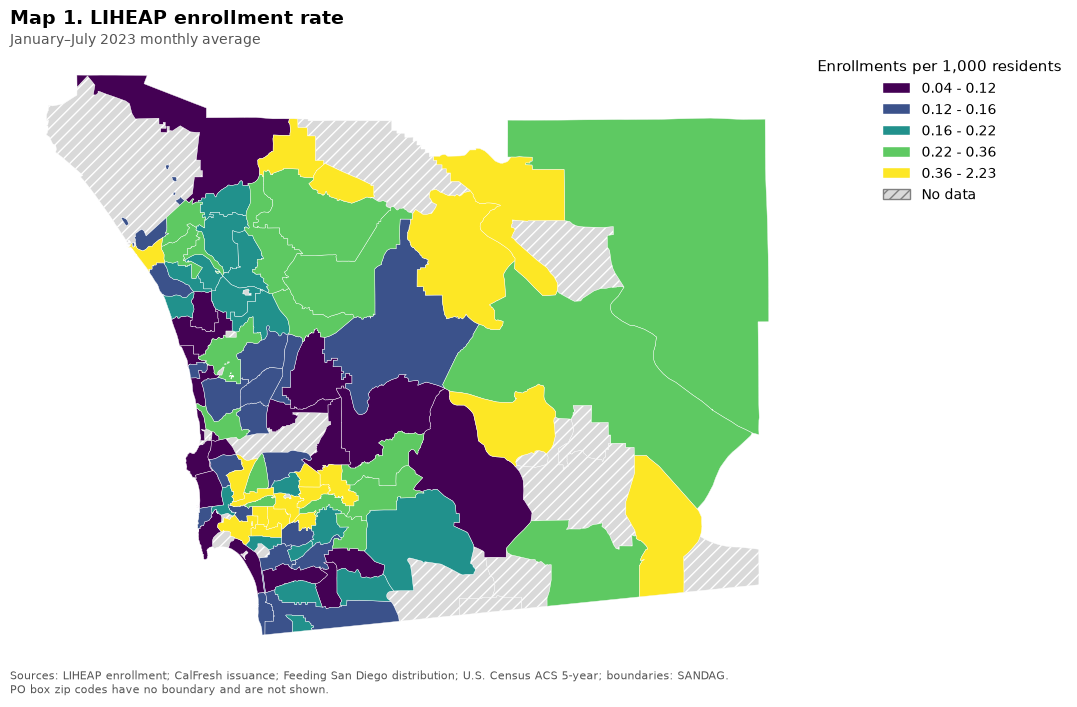

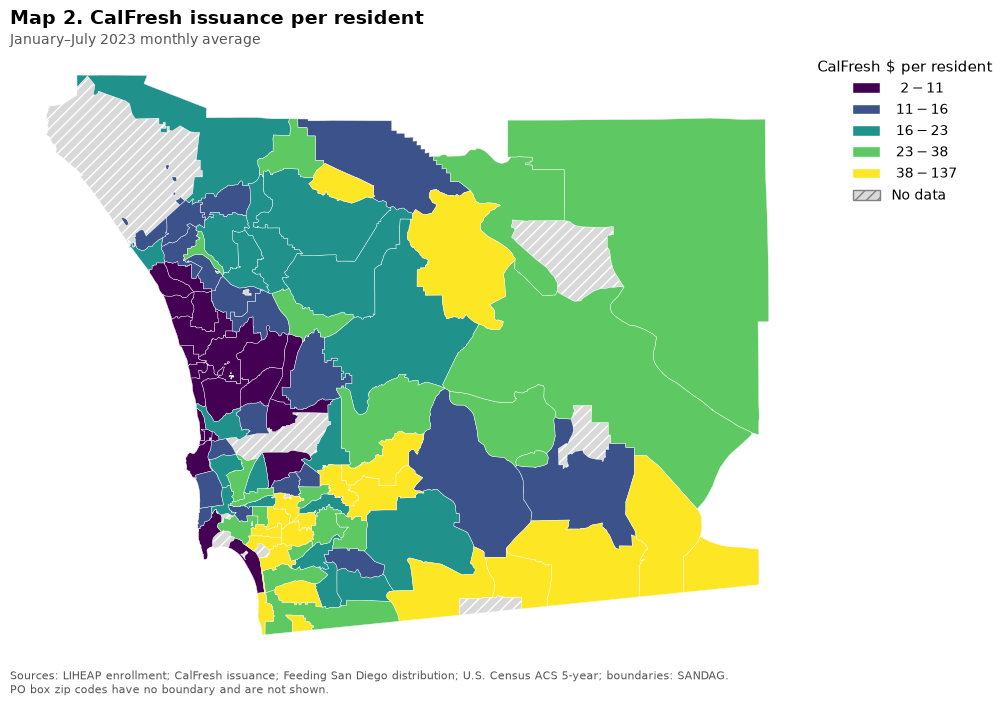

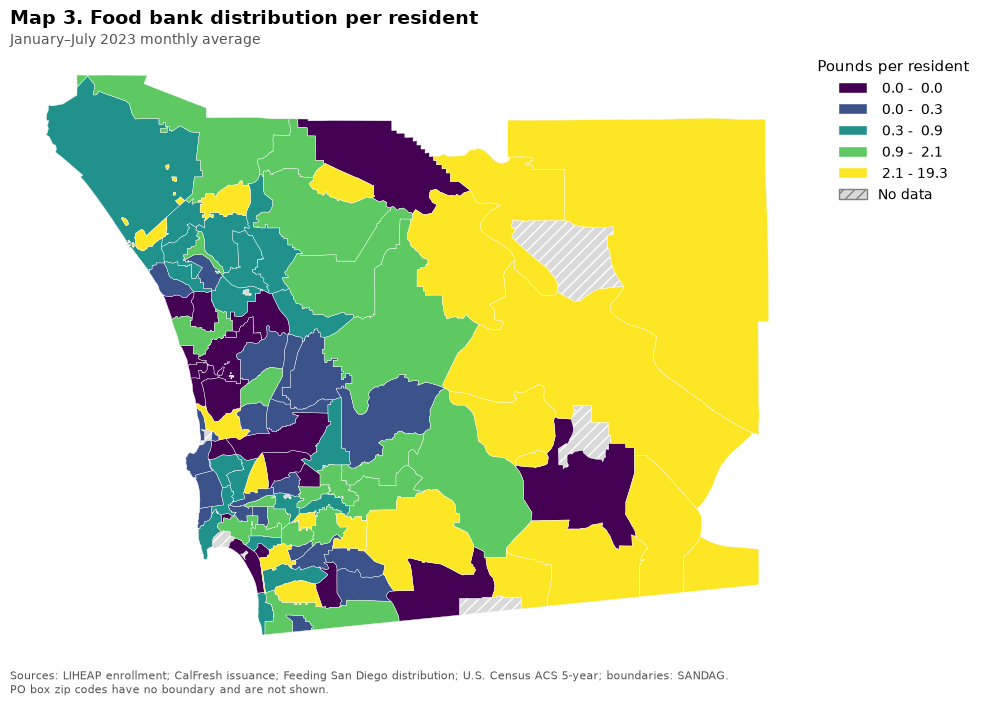

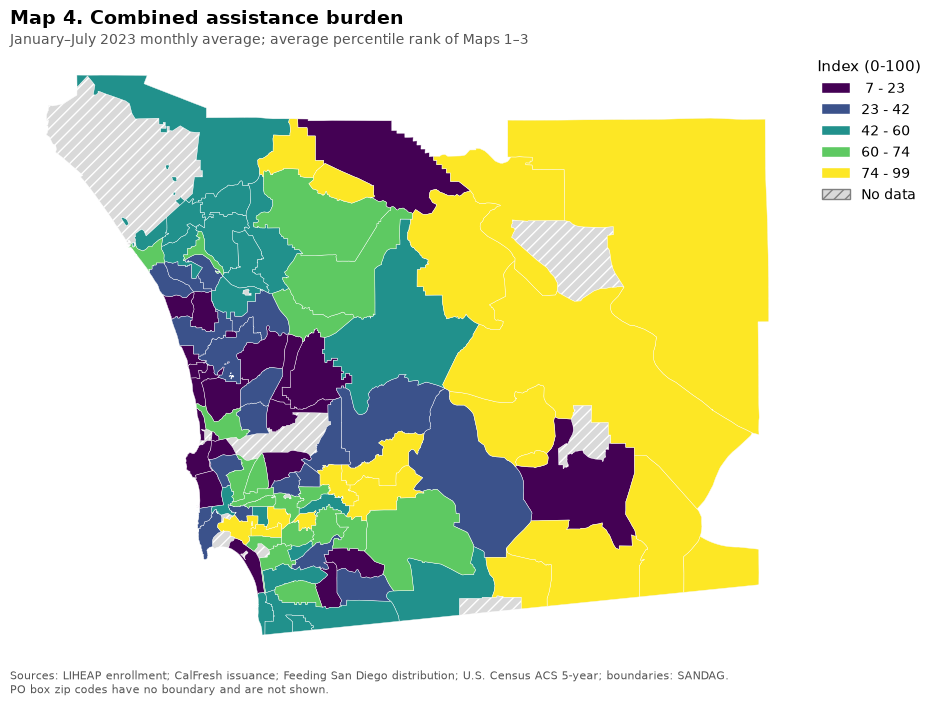

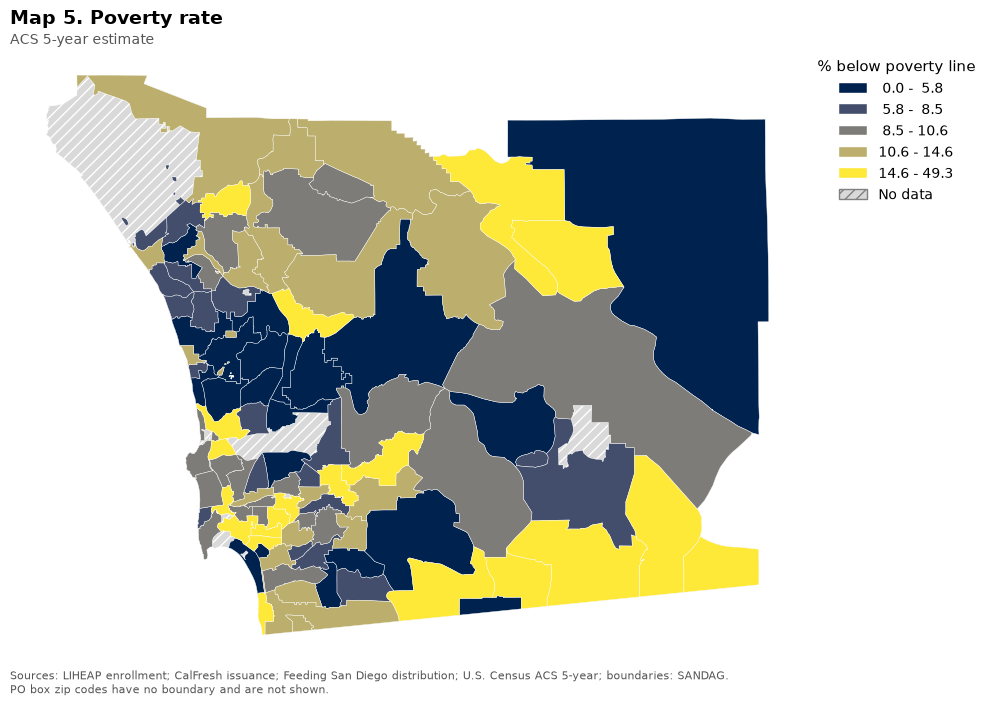

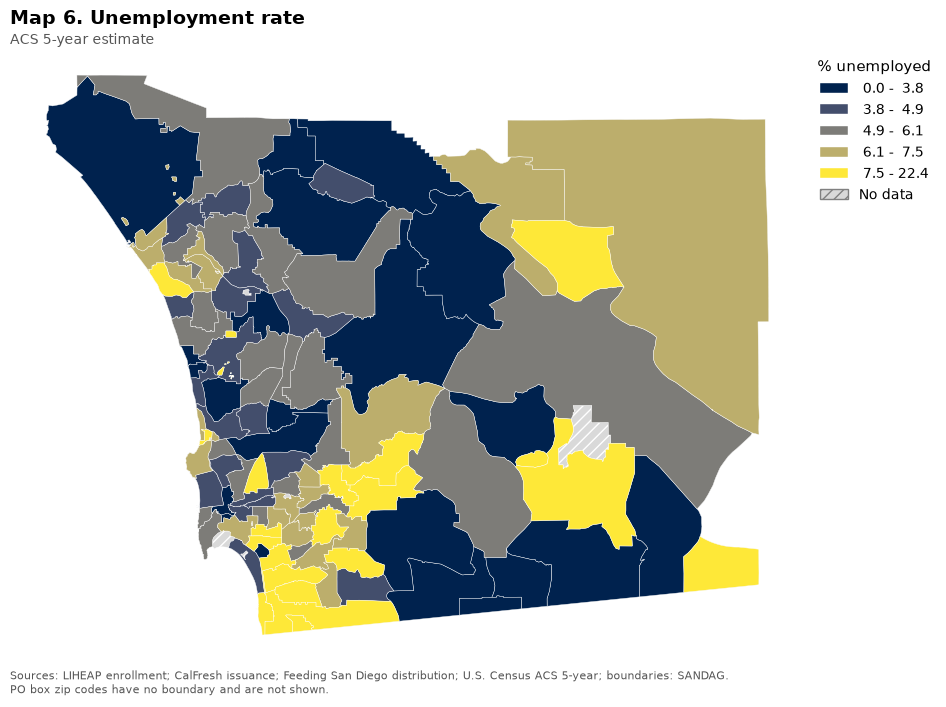

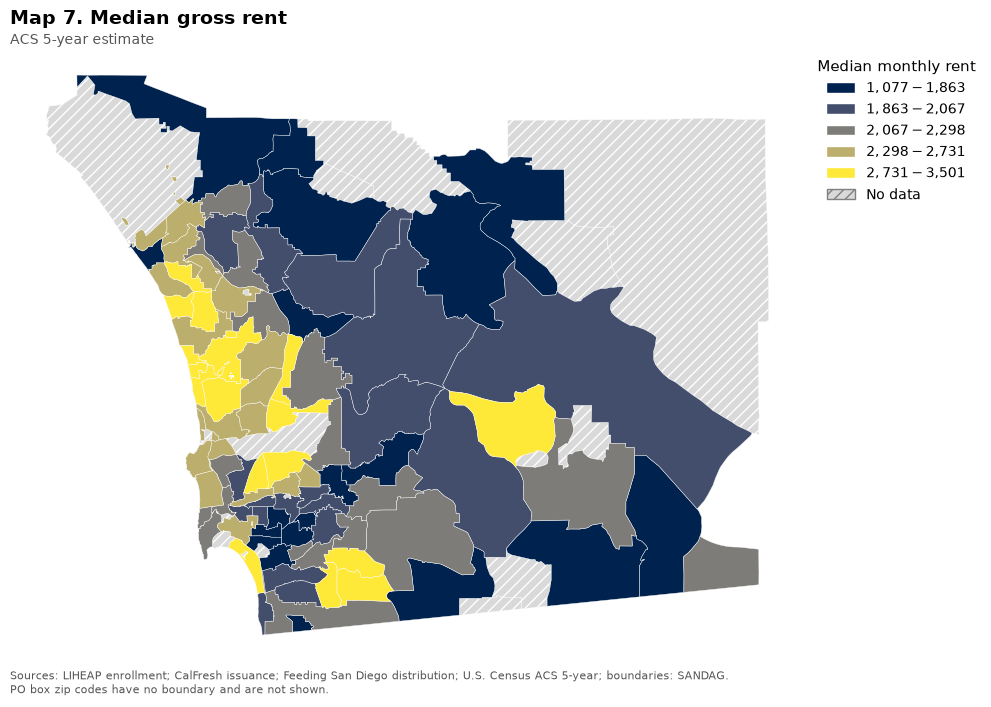

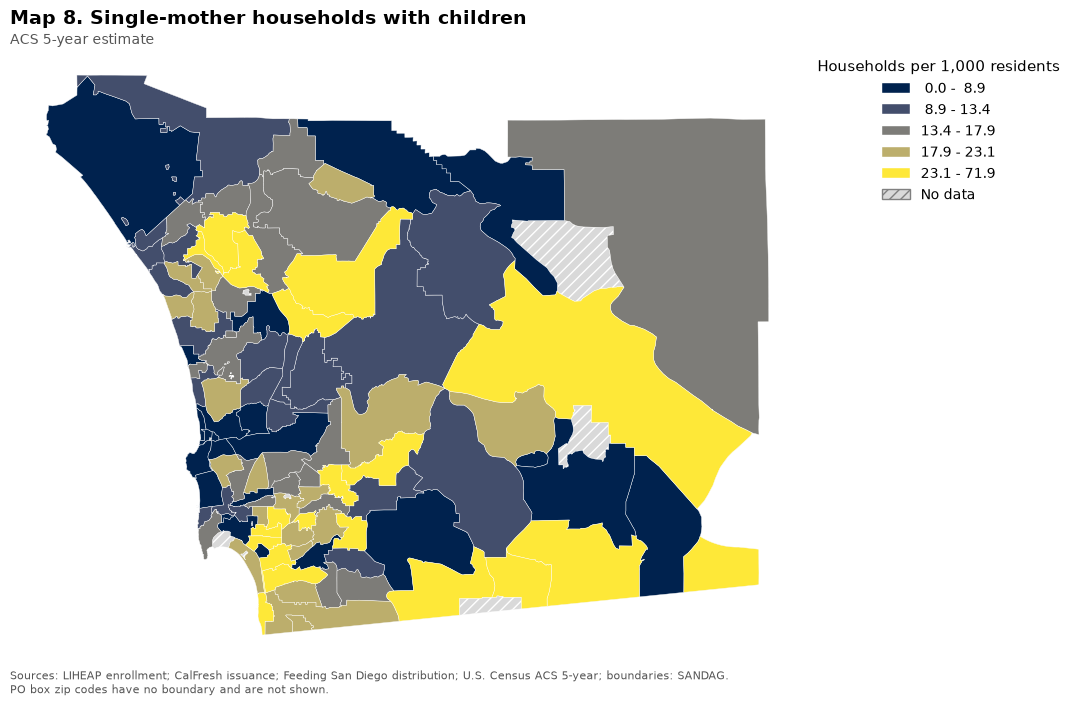

In [35]:
#LIHEAP map 
make_map("LIHEAP_per_1k", "Map 1. LIHEAP enrollment rate", "Enrollments per 1,000 residents",
        fmt="{:,.2f}", fname="Map1_LIHEAP.png")
#calfresh per capita
make_map("CalFresh_per_capita", "Map 2. CalFresh issuance per resident", "CalFresh $ per resident",
         fmt="${:,.0f}", fname="Map2_CalFresh.png")
#foodbank pounds distribution per resident 
make_map("FSD_lbs_per_capita", "Map 3. Food bank distribution per resident", "Pounds per resident",
        fname="Map3_FoodBank.png")
#make map of assistance burden 
make_map("Assistance_Burden_Index", "Map 4. Combined assistance burden", "Index (0-100)",
        fmt="{:,.0f}", note=PERIOD + "; average percentile rank of Maps 1–3", fname="Map4_Combined.png")

ACS = "ACS 5-year estimate"
make_map("Poverty_Rate_Pct", "Map 5. Poverty rate", "% below poverty line", cmap="cividis", note=ACS, fname="Map5_Poverty.png")
make_map("Unemployment_Rate_Pct", "Map 6. Unemployment rate", "% unemployed", cmap="cividis", note=ACS, fname="Map6_Unemployment.png")
make_map("Median_Gross_Rent", "Map 7. Median gross rent", "Median monthly rent", cmap="cividis",
        fmt="${:,.0f}", note=ACS, fname="Map7_Rent.png")
make_map("Single_Mothers_per_1k", "Map 8. Single-mother households with children",
        "Households per 1,000 residents", cmap="cividis", note=ACS, fname="Map8_SingleMothers.png")

**Identify Spatial Clusters from the Data**

In [36]:
import numpy as np
import pandas as pd
from libpysal.weights import Queen, KNN, attach_islands
from esda.moran import Moran, Moran_Local

**Create global and local morans i for each program**

In [37]:
VARS = {"LIHEAP_per_1k": "LIHEAP", "CalFresh_per_capita": "CalFresh", "FSD_lbs_per_capita": "FoodBank", "Assistance_Burden_Index": "Combined"}
ALPHA, PERMS, SEED = 0.05, 999, 42
QUAD = {
    1: "Hot spot (High-High)",
    2: "Low outlier (Low-High)",
    3: "Cold spot (Low-Low)",
    4: "High outlier (High-Low)",
}

NOT_SIG = "Not significant"

In [38]:
def build_weights(sub):
    """
    Build a spatial weights matrix that defines which zip codes are neighbors.

    1. Queen contiguity: zip codes that share a border or a corner are neighbors.
    2. Islands: any zip code with no touching neighbor (e.g., Coronado or an
       isolated rural zip) is linked to its single nearest zip code, so it is
       not dropped from the analysis.
    3. Row-standardization: each zip's neighbor weights sum to 1, so the
       neighbor value is an average and zips with many neighbors don't dominate.
    """
    w = Queen.from_dataframe(sub, use_index=False, silence_warnings=True)
    if w.islands:
        nearest = KNN.from_dataframe(sub, k=1)
        w = attach_islands(w, nearest)

    w.transform="r"
    return w

np.random.seed(SEED)

clusters = gdf[["Zip_Code", "City"]].copy()
global_rows = []
for col, name in VARS.items():
    sub = gdf[gdf[col].notna()].reset_index(drop=True)
    w = build_weights(sub)
    y = sub[col].values

    mi = Moran(y, w, permutations=PERMS)
    global_rows.append(dict(Variable=name, Morans_I=round(mi.I, 3), p_value=mi.p_sim, n=len(sub)))

    lisa = Moran_Local(y, w, permutations=PERMS, seed=SEED)
    lab = np.where(lisa.p_sim < ALPHA, pd.Series(lisa.q).map(QUAD).values, NOT_SIG)
    out = pd.DataFrame({"Zip_Code": sub["Zip_Code"], f"{name}_Cluster": lab,
                       f"{name}_p": lisa.p_sim.round(3)})
    clusters = clusters.merge(out, on="Zip_Code", how="left")

progs = ["LIHEAP", "CalFresh", "FoodBank"]
for c in [f"{p}_Cluster" for p in progs] + ["Combined_Cluster"]:
    clusters[c] = clusters[c].fillna("No data")

global_moran = pd.DataFrame(global_rows)
display(global_moran)
display(clusters[[f"{p}_Cluster" for p in progs] + ["Combined_Cluster"]].apply(pd.Series.value_counts).fillna(0).astype(int).drop(index=NOT_SIG, errors="ignore"))

,Variable,Morans_I,p_value,n
0,LIHEAP,0.206,0.003,89
1,CalFresh,0.341,0.001,97
2,FoodBank,0.064,0.105,100
3,Combined,0.341,0.001,96


,LIHEAP_Cluster,CalFresh_Cluster,FoodBank_Cluster,Combined_Cluster
Cold spot (Low-Low),13,21,7,13
High outlier (High-Low),1,0,2,1
Hot spot (High-High),4,4,2,5
Low outlier (Low-High),0,2,3,3
No data,21,13,10,14


In [39]:
HOT = QUAD[1]
COLD = QUAD[3]

prog_cols = [f"{p}_Cluster" for p in progs]
c = clusters[prog_cols]

clusters["n_HotSpots"] = (c == HOT).sum(axis=1)
clusters["n_ColdSpots"] = (c == COLD).sum(axis=1)
clusters["n_NoData"] = (c == "No data").sum(axis=1)

def pattern(row):
    """Classify how the three programs line up in each zip code."""
    hot, cold = row["n_HotSpots"], row["n_ColdSpots"]
    if row["n_NoData"] == len(progs):
        return "No data"
    elif hot >= 2:
        return "Overlap: high need"
    elif hot >= 1 and cold >= 1:
        return "Divergent"
    elif hot == 1:
        return "Single-program hot spot"
    elif cold >= 2:
        return "Overlap: low need"
    if cold == 1:
        return "Single-program cold spot"
    else:
        return "No significant cluster"

In [40]:
clusters["Program_Pattern"] = clusters.apply(pattern, axis=1)

In [41]:
clusters["Hot_Programs"] = c.apply(lambda r: ", ".join(p for p in progs if r[f"{p}_Cluster"] == HOT), axis=1)
clusters["Cold_Programs"] = c.apply(lambda r: ", ".join(p for p in progs if r[f"{p}_Cluster"] == COLD), axis=1)    

In [42]:
display(clusters["Program_Pattern"].value_counts())

Program_Pattern
No significant cluster      60
Single-program cold spot    23
No data                      9
Overlap: low need            9
Single-program hot spot      8
Overlap: high need           1
Name: count, dtype: int64

In [43]:
show = ["Zip_Code", "City"] + prog_cols + ["Combined_Cluster"]

print("Concentrations of high assistance need (combined hot spots):")
display(clusters[clusters["Combined_Cluster"] == HOT][["Zip_Code", "City", "Hot_Programs"]])

print("Programs overlap: hot spot in 2+ programs:")
display(clusters[clusters["Program_Pattern"] == "Overlap: high need"][show])

print("Programs diverge: hot in one program, cold in another:")
display(clusters[clusters["Program_Pattern"] == "Divergent"][["Zip_Code", "City", "Hot_Programs", "Cold_Programs"]])

print("Possible service gaps: low assistance among high-need neighbors (combined):")
display(clusters[clusters["Combined_Cluster"] == QUAD[2]][["Zip_Code", "City"]])

Concentrations of high assistance need (combined hot spots):


,Zip_Code,City,Hot_Programs
13,91934,Jacumba,CalFresh
15,91941,La Mesa,
26,92004,Borrego Springs,
82,92114,San Diego,CalFresh
83,92115,San Diego,


Programs overlap: hot spot in 2+ programs:


,Zip_Code,City,LIHEAP_Cluster,CalFresh_Cluster,FoodBank_Cluster,Combined_Cluster
3,91906,Campo,Not significant,Hot spot (High-High),Hot spot (High-High),Not significant


Programs diverge: hot in one program, cold in another:


,Zip_Code,City,Hot_Programs,Cold_Programs


Possible service gaps: low assistance among high-need neighbors (combined):


,Zip_Code,City
0,91901,Alpine
20,91962,Pine Valley
51,92060,Palomar Mountain


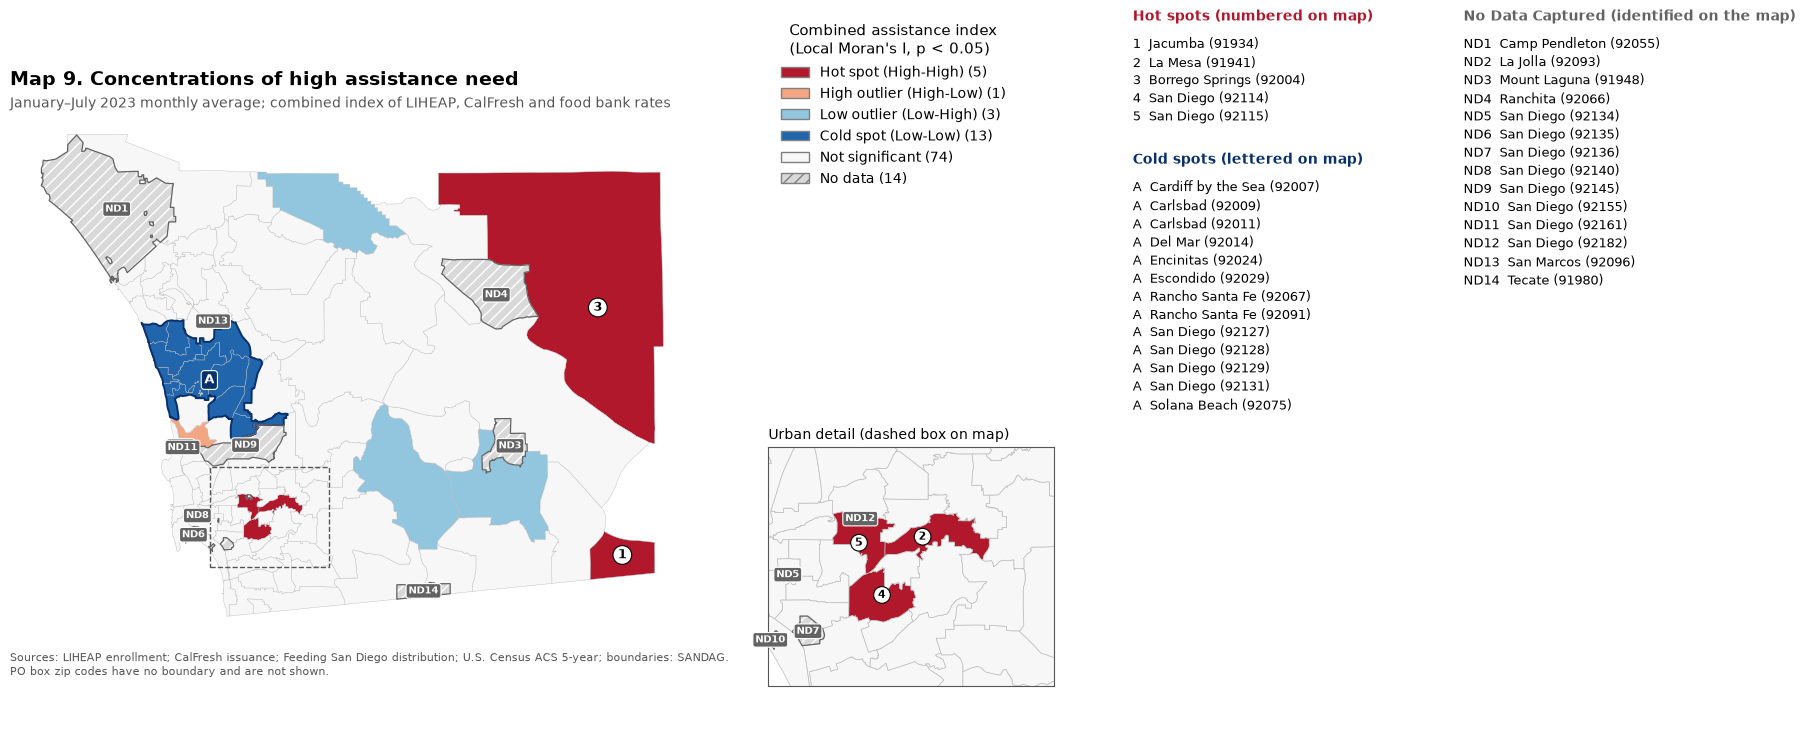

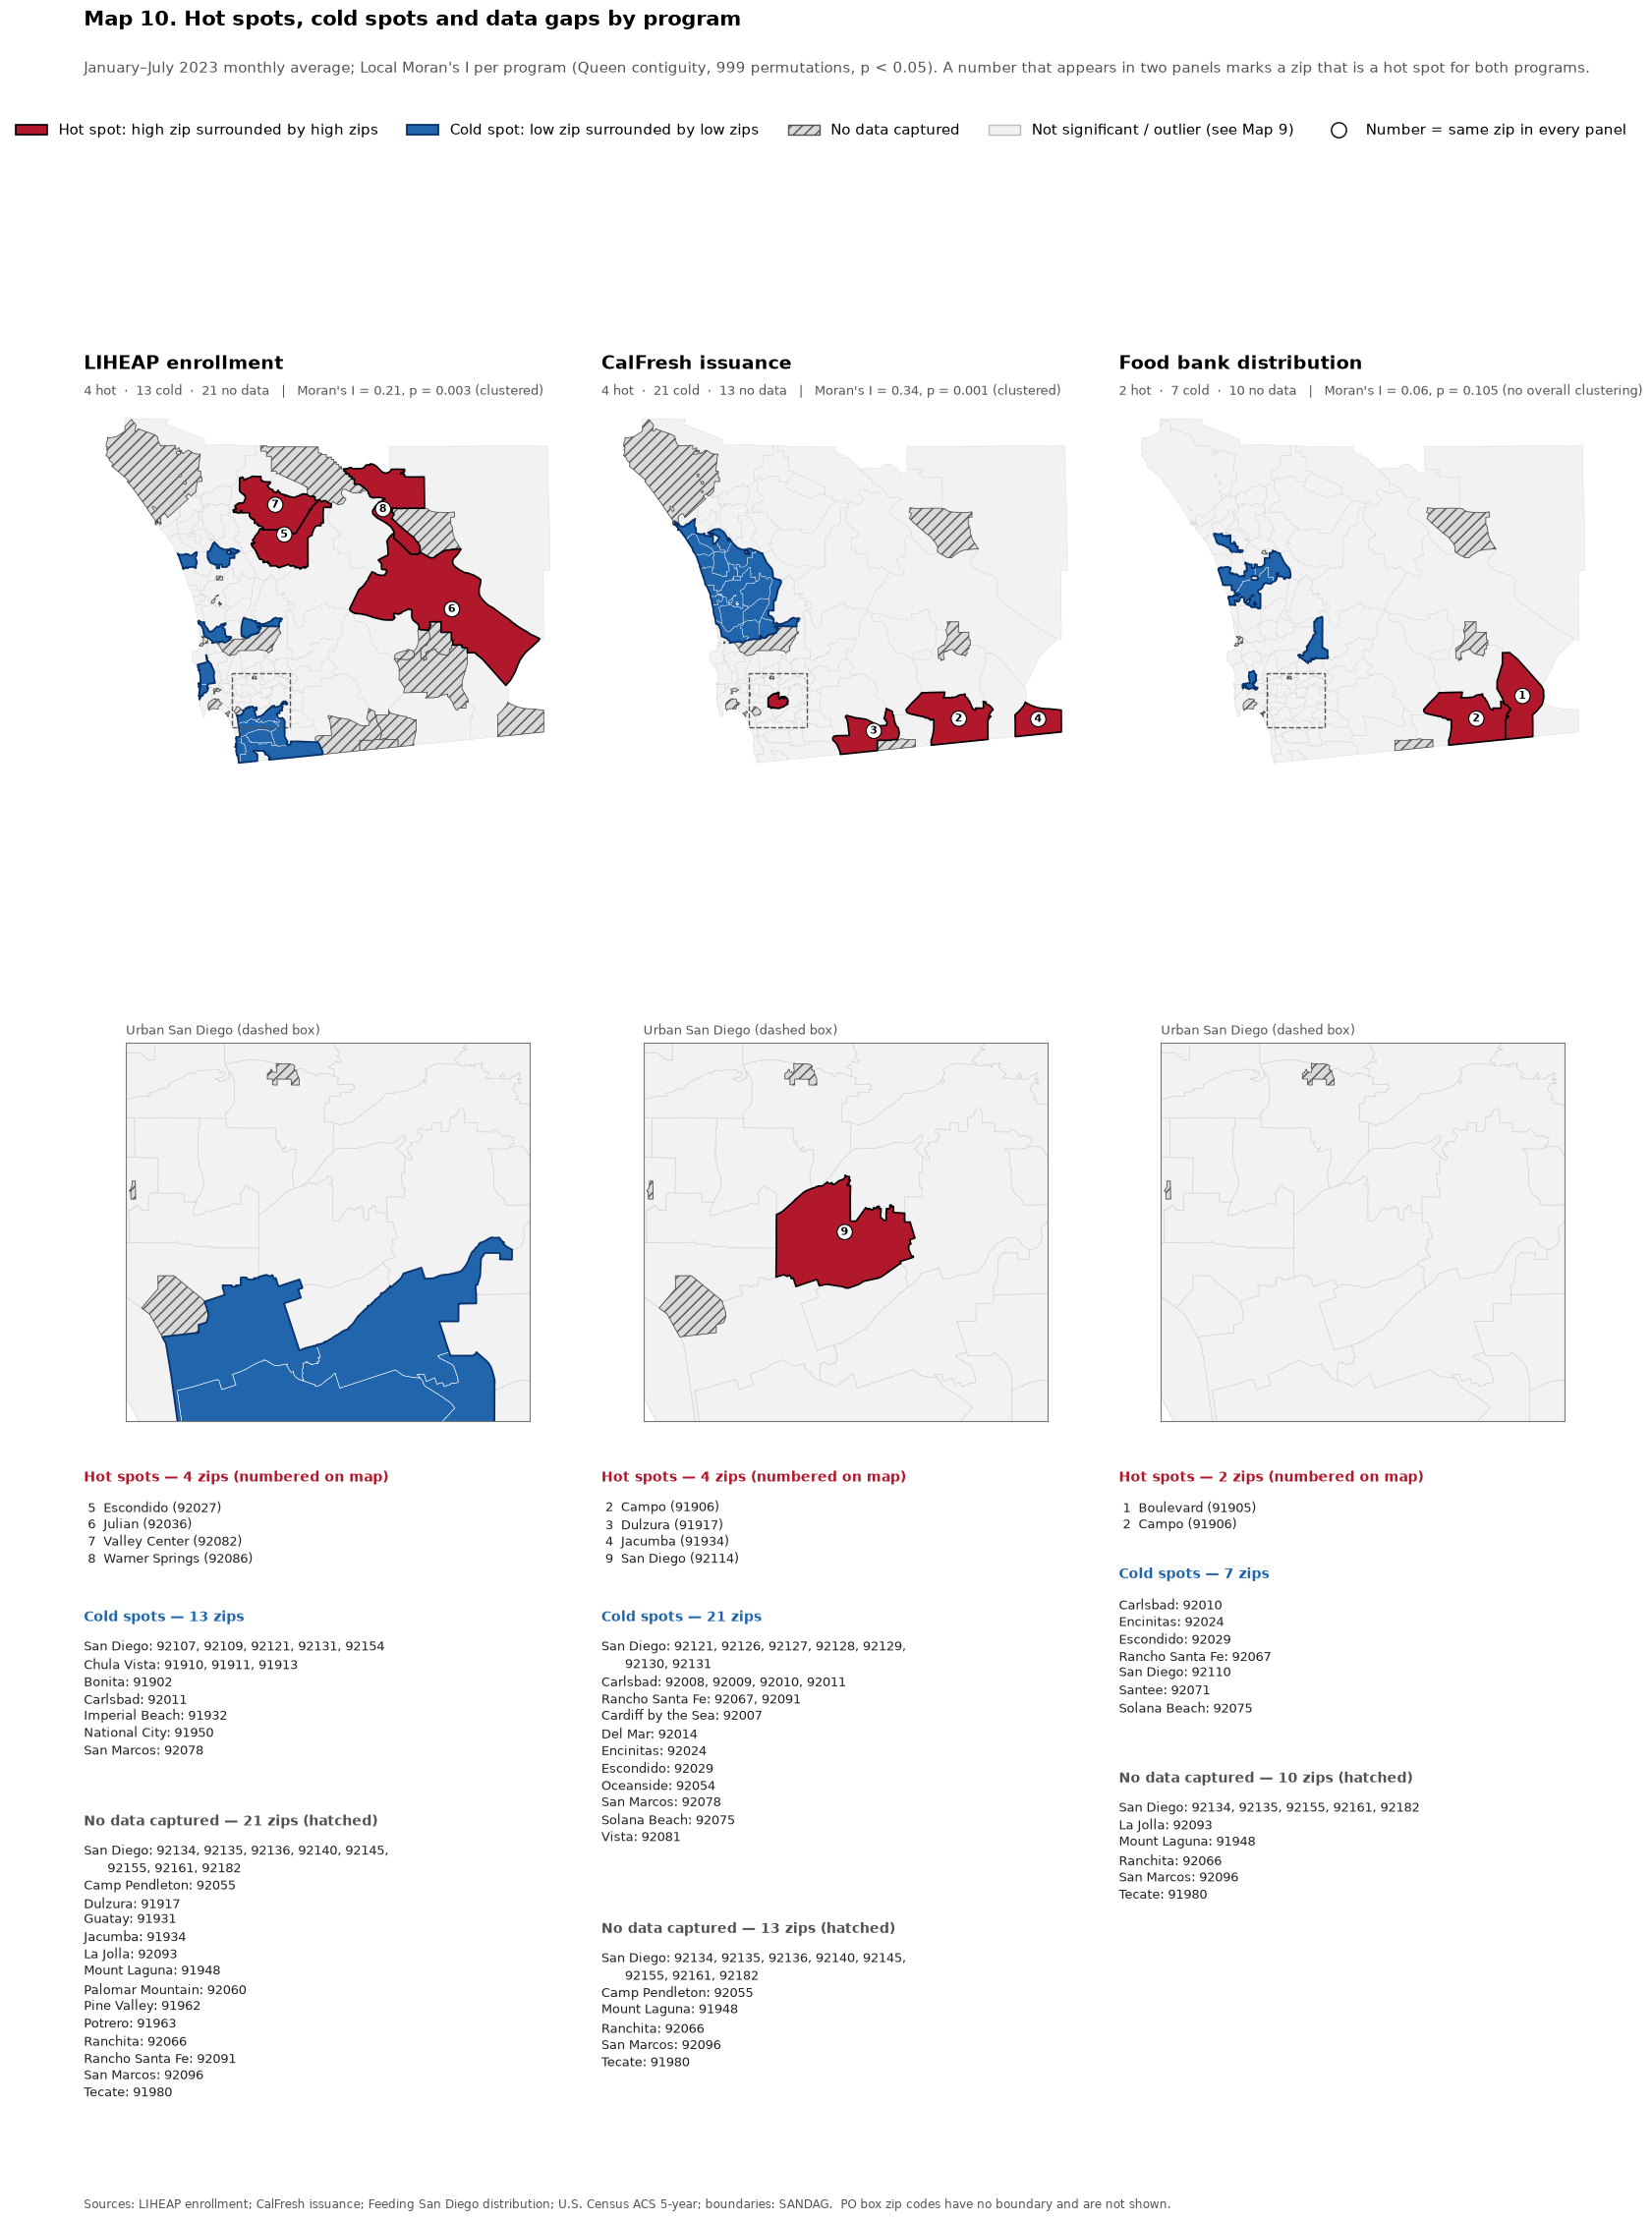

In [44]:
import string
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

gdf_c = gdf[["Zip_Code", "geometry"]].merge(clusters, on="Zip_Code")

# =========================================================
# Shared helpers
# =========================================================
NODATA_STYLE = dict(color="#d9d9d9", edgecolor="white", linewidth=0.3, hatch="///")

def draw_categories(ax, data, col, colors, lw=0.3):
    """Fill zips by category; return legend handles/labels for categories present (with counts)."""
    handles, labels = [], []
    for label, color in colors.items():
        part = data[data[col] == label]
        if len(part):
            part.plot(ax=ax, color=color, edgecolor="#bdbdbd", linewidth=lw)
            handles.append(Patch(facecolor=color, edgecolor="grey"))
            labels.append(f"{label} ({len(part)})")
    nod = data[data[col] == "No data"]
    if len(nod):
        nod.plot(ax=ax, **NODATA_STYLE)
        handles.append(Patch(facecolor="#d9d9d9", edgecolor="grey", hatch="///"))
        labels.append(f"No data ({len(nod)})")
    return handles, labels

def finish(ax, title, subtitle, fname):
    """Title, subtitle, source line, save and show."""
    ax.set_title(title, fontsize=14, fontweight="bold", loc="left", pad=18)
    ax.text(0, 1.005, subtitle, transform=ax.transAxes, fontsize=10, color="#555")
    ax.set_axis_off()
    ax.text(0, -0.02, SOURCE + "\nPO box zip codes have no boundary and are not shown.",
            transform=ax.transAxes, va="top", fontsize=8, color="#555")
    save_map(fname)
    plt.show()

def marker(ax, x, y, text, fc, ec, color, shape="circle", size=9):
    """Small labelled marker on the map."""
    box_style = dict(boxstyle=f"{shape},pad=0.25", fc=fc, ec=ec, lw=0.8)
    ax.annotate(text, (x, y), ha="center", va="center", fontsize=size,
                fontweight="bold", color=color, bbox=box_style)

def number_marker(ax, row, size=9):      # hot spots: white circle, black number
    marker(ax, row["pt"].x, row["pt"].y, str(row["Num"]), "white", "black", "black", "circle", size)

def letter_marker(ax, row, size=9):      # cold-spot areas: navy box, white letter
    marker(ax, row["pt"].x, row["pt"].y, row["Letter"], "#08306b", "white", "white", "round", size)

def nodata_marker(ax, row, size=7):      # no-data zips: grey box, "ND#" label
    marker(ax, row["pt"].x, row["pt"].y, row["ND"], "#636363", "white", "white", "round", size)

def write_section(ax, y, header, lines, color, fontsize=9, gap=1.45):
    """Write a bold coloured header and its lines in a side panel; return the next free y."""
    panel_h = ax.figure.get_size_inches()[1] * ax.get_position().height   # panel height (inches)
    line_h = fontsize * gap / 72 / panel_h                                  # one line in axes units
    ax.text(0.02, y, header, transform=ax.transAxes, va="top",
            fontsize=fontsize + 1, fontweight="bold", color=color)
    y -= line_h * 1.4
    if lines:
        ax.text(0.02, y, "\n".join(lines), transform=ax.transAxes, va="top",
                fontsize=fontsize, linespacing=gap)
    return y - line_h * (len(lines) + 1.5)

# =========================================================
# Map 9: Concentrations of high assistance need (combined index)
# =========================================================
lisa_colors = {                 # colorblind-safe red–blue
    QUAD[1]: "#b2182b",         # Hot spot (High-High)
    QUAD[4]: "#f4a582",         # High outlier (High-Low)
    QUAD[2]: "#92c5de",         # Low outlier (Low-High)
    QUAD[3]: "#2166ac",         # Cold spot (Low-Low)
    NOT_SIG: "#f7f7f7",         # Not significant
}

# Layout: map | legend + urban detail | key (hot + cold) | key (no data)
fig, axd = plt.subplot_mosaic([["map", "legend", "key", "key2"], ["map", "detail", "key", "key2"]],
                              figsize=(22, 9.5), width_ratios=[2.4, 1, 0.9, 0.9], height_ratios=[1, 1.1])
ax, lax, kax, kax2, dax = axd["map"], axd["legend"], axd["key"], axd["key2"], axd["detail"]

handles, labels = draw_categories(ax, gdf_c, "Combined_Cluster", lisa_colors)

# ---- Hot spots: numbered ----
hot = gdf_c[gdf_c["Combined_Cluster"] == HOT].copy()
hot["pt"] = hot.geometry.representative_point()
hot = hot.sort_values("Zip_Code").reset_index(drop=True)
hot["Num"] = hot.index + 1

# ---- Cold spots: merge touching cold-spot zips into areas, letter them north → south ----
cold = gdf_c[gdf_c["Combined_Cluster"] == COLD].copy()
cold_rows, regions = [], None
if len(cold):
    regions = cold.dissolve().explode(index_parts=False).reset_index(drop=True)[["geometry"]]
    regions["pt"] = regions.geometry.representative_point()
    regions["y"] = regions["pt"].apply(lambda p: p.y)
    regions = regions.sort_values("y", ascending=False).reset_index(drop=True)
    regions["Letter"] = list(string.ascii_uppercase[:len(regions)])

    cold["pt"] = cold.geometry.representative_point()
    for _, reg in regions.iterrows():
        members = cold[cold["pt"].within(reg.geometry)].sort_values(["City", "Zip_Code"])
        for _, m in members.iterrows():
            cold_rows.append(f"{reg['Letter']}  {m['City']} ({m['Zip_Code']})")

    regions.boundary.plot(ax=ax, color="#08306b", linewidth=1.4)
    for _, reg in regions.iterrows():
        letter_marker(ax, reg)

# ---- No data captured: outline and mark each zip (ND1, ND2, ...) ----
nodata = gdf_c[gdf_c["Combined_Cluster"] == "No data"].copy()
nodata["pt"] = nodata.geometry.representative_point()
nodata = nodata.sort_values(["City", "Zip_Code"]).reset_index(drop=True)
nodata["ND"] = [f"ND{i + 1}" for i in nodata.index]
nodata_rows = [f"{r['ND']}  {r['City']} ({r['Zip_Code']})" for _, r in nodata.iterrows()]
if len(nodata):
    nodata.boundary.plot(ax=ax, color="#636363", linewidth=0.9)

# ---- Urban detail panel: zoom on the small (urban) hot spots ----
small = hot[hot.geometry.area < 100e6]          # zips under 100 km²
in_box = lambda pts, b: pts.apply(lambda p: b[0] <= p.x <= b[2] and b[1] <= p.y <= b[3])
if len(small):
    pad = 6000                                   # metres of margin around the zoom
    x0, y0, x1, y1 = small.total_bounds
    bounds = (x0 - pad, y0 - pad, x1 + pad, y1 + pad)

    draw_categories(dax, gdf_c, "Combined_Cluster", lisa_colors, lw=0.5)
    if regions is not None:
        regions.boundary.plot(ax=dax, color="#08306b", linewidth=1.2)
    if len(nodata):
        nodata.boundary.plot(ax=dax, color="#636363", linewidth=0.9)
    for _, r in hot.iterrows():
        number_marker(dax, r, size=8)
    for _, r in nodata[in_box(nodata["pt"], bounds)].iterrows():
        nodata_marker(dax, r)

    dax.set_xlim(bounds[0], bounds[2]); dax.set_ylim(bounds[1], bounds[3])
    dax.set_xticks([]); dax.set_yticks([]); dax.set_xlabel(""); dax.set_ylabel("")
    for sp in dax.spines.values():
        sp.set_edgecolor("#555")
    dax.set_title("Urban detail (dashed box on map)", fontsize=10, loc="left")
    ax.add_patch(Rectangle((bounds[0], bounds[1]), bounds[2] - bounds[0], bounds[3] - bounds[1],
                           fill=False, edgecolor="#555", linewidth=1, linestyle="--"))
    hot_main = hot[~hot.index.isin(small.index)]                  # urban numbers only in the zoom
    nodata_main = nodata[~in_box(nodata["pt"], bounds)]           # urban ND marks only in the zoom
else:
    dax.set_axis_off()
    hot_main, nodata_main = hot, nodata

for _, r in hot_main.iterrows():
    number_marker(ax, r)
for _, r in nodata_main.iterrows():
    nodata_marker(ax, r)

# ---- Legend ----
lax.set_axis_off()
lax.legend(handles, labels, title="Combined assistance index\n(Local Moran's I, p < 0.05)",
           loc="upper left", frameon=False, fontsize=10, title_fontsize=11)

# ---- Side keys ----
hot_rows = [f"{r['Num']}  {r['City']} ({r['Zip_Code']})" for _, r in hot.iterrows()]

kax.set_axis_off()
y = write_section(kax, 1.0, "Hot spots (numbered on map)", hot_rows, "#b2182b")
write_section(kax, y, "Cold spots (lettered on map)", cold_rows, "#08306b")

kax2.set_axis_off()
write_section(kax2, 1.0, "No Data Captured (identified on the map)", nodata_rows, "#636363")

finish(ax, "Map 9. Concentrations of high assistance need",
       PERIOD + "; combined index of LIHEAP, CalFresh and food bank rates",
       "Map9_Combined_Clusters.png")

# =========================================================
# Map 10: Hot spots, cold spots and no-data zips, program by program
# =========================================================
import textwrap
from matplotlib.lines import Line2D

PROGRAMS = ["LIHEAP", "CalFresh", "FoodBank"]
PROGRAM_TITLES = {"LIHEAP": "LIHEAP enrollment",
                  "CalFresh": "CalFresh issuance",
                  "FoodBank": "Food bank distribution"}
gm = global_moran.set_index("Variable")

# Three things to see; everything else fades into the background
HOT_C, COLD_C, OTHER_C = "#b2182b", "#2166ac", "#f2f2f2"
ND_FACE, ND_EDGE = "#d9d9d9", "#525252"

# One number per hot-spot zip, shared by all three panels
hot_any = gdf_c[gdf_c[[f"{p}_Cluster" for p in PROGRAMS]].eq(HOT).any(axis=1)].copy()
hot_any["pt"] = hot_any.geometry.representative_point()
hot_any = hot_any.sort_values("Zip_Code").reset_index(drop=True)
hot_any["Num"] = hot_any.index + 1

# Shared zoom on the small urban hot spots
small = hot_any[hot_any.geometry.area < 100e6]          # zips under 100 km²
zoom = None
if len(small):
    pad = 6000                                            # metres
    x0, y0, x1, y1 = small.total_bounds
    zoom = (x0 - pad, y0 - pad, x1 + pad, y1 + pad)
in_zoom = lambda p: zoom is not None and zoom[0] <= p.x <= zoom[2] and zoom[1] <= p.y <= zoom[3]

def hot_number(ax, r):
    ax.annotate(str(r["Num"]), (r["pt"].x, r["pt"].y), ha="center", va="center",
                fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="black", lw=0.8))

def draw_panel(ax, col, lw=0.25):
    """Background + hot (red) + cold (blue, outlined areas) + no data (hatched)."""
    hot  = gdf_c[gdf_c[col] == HOT]
    cold = gdf_c[gdf_c[col] == COLD]
    nod  = gdf_c[gdf_c[col] == "No data"]
    rest = gdf_c[~gdf_c[col].isin([HOT, COLD, "No data"])]

    rest.plot(ax=ax, color=OTHER_C, edgecolor="#d0d0d0", linewidth=lw)
    if len(nod):
        nod.plot(ax=ax, facecolor=ND_FACE, edgecolor=ND_EDGE, linewidth=0.6, hatch="///")
    if len(cold):
        cold.plot(ax=ax, color=COLD_C, edgecolor="white", linewidth=lw)
        cold.dissolve().boundary.plot(ax=ax, color="#08306b", linewidth=1.3)
    if len(hot):
        hot.plot(ax=ax, color=HOT_C, edgecolor="black", linewidth=1.2)
    return hot, cold, nod

# ---- Key text: every hot, cold and no-data zip, grouped by city ----
def city_zips(df):
    """One line per city, listing its zips: 'Carlsbad: 92009, 92011'."""
    if df.empty:
        return []
    grouped = df.sort_values("Zip_Code").groupby("City")["Zip_Code"].apply(list)
    order = grouped.str.len().sort_values(ascending=False, kind="stable").index   # biggest first
    return [f"{city}: {', '.join(map(str, grouped[city]))}" for city in order]

WRAP = 46                                                 # characters per line
def wrapped(lines):
    out = []
    for l in lines:
        out += textwrap.wrap(l, WRAP, subsequent_indent="      ")
    return out or ["None"]

keys = {}
for prog in PROGRAMS:
    col = f"{prog}_Cluster"
    hot_rows = hot_any[hot_any[col] == HOT]
    keys[prog] = [
        (f"Hot spots — {len(hot_rows)} zips (numbered on map)",
         wrapped([f"{r['Num']:>2}  {r['City']} ({r['Zip_Code']})" for _, r in hot_rows.iterrows()]), HOT_C),
        (f"Cold spots — {(gdf_c[col] == COLD).sum()} zips",
         wrapped(city_zips(gdf_c[gdf_c[col] == COLD])), COLD_C),
        (f"No data captured — {(gdf_c[col] == 'No data').sum()} zips (hatched)",
         wrapped(city_zips(gdf_c[gdf_c[col] == "No data"])), ND_EDGE),
    ]

LINE_IN = 9 * 1.75 / 72                                   # one text line, inches

def key_text(ax, sections):
    """Coloured header + body lines for each section, stacked top to bottom."""
    ax.set_axis_off()
    panel_h = ax.figure.get_size_inches()[1] * ax.get_position().height
    line = LINE_IN / panel_h
    y = 1.0
    for header, lines, color in sections:
        ax.text(0, y, header, transform=ax.transAxes, va="top",
                fontsize=10, fontweight="bold", color=color)
        y -= line * 1.3
        ax.text(0, y, "\n".join(lines), transform=ax.transAxes, va="top",
                fontsize=9, linespacing=1.4, color="#222")
        y -= line * (len(lines) + 1.2)

# key row grows with the longest list so nothing is cut off
max_lines = max(sum(len(body) + 2.5 for _, body, _ in secs) for secs in keys.values())
key_h = max_lines * LINE_IN
map_h, zoom_h = 8.5, 4.0

# ---- Layout: maps on top, urban zoom in the middle, keys underneath ----
fig, axd = plt.subplot_mosaic(
    [[f"map_{p}" for p in PROGRAMS],
     [f"zoom_{p}" for p in PROGRAMS],
     [f"key_{p}" for p in PROGRAMS]],
    figsize=(20, map_h + zoom_h + key_h + 3), height_ratios=[map_h, zoom_h, key_h],
    gridspec_kw=dict(wspace=0.06, hspace=0.08, top=0.92, bottom=0.04))

for prog in PROGRAMS:
    col = f"{prog}_Cluster"
    ax, zax, kax = axd[f"map_{prog}"], axd[f"zoom_{prog}"], axd[f"key_{prog}"]
    hot, cold, nod = draw_panel(ax, col)
    prog_hot = hot_any[hot_any["Zip_Code"].isin(hot["Zip_Code"])]

    # main map: numbers only for hot zips outside the zoom box
    for _, r in prog_hot.iterrows():
        if not in_zoom(r["pt"]):
            hot_number(ax, r)
    ax.set_axis_off()

    # urban zoom
    if zoom is not None:
        draw_panel(zax, col, lw=0.4)
        for _, r in prog_hot.iterrows():
            hot_number(zax, r)
        zax.set_xlim(zoom[0], zoom[2]); zax.set_ylim(zoom[1], zoom[3])
        zax.set_xticks([]); zax.set_yticks([]); zax.set_xlabel(""); zax.set_ylabel("")
        zax.set_aspect("equal")
        for sp in zax.spines.values():
            sp.set_edgecolor("#777")
        zax.set_title("Urban San Diego (dashed box)", fontsize=9, loc="left", color="#555")
        ax.add_patch(Rectangle((zoom[0], zoom[1]), zoom[2] - zoom[0], zoom[3] - zoom[1],
                               fill=False, edgecolor="#555", linewidth=1, linestyle="--"))
    else:
        zax.set_axis_off()

    # title + one-line stats
    I, p = gm.loc[prog, "Morans_I"], gm.loc[prog, "p_value"]
    sig = "clustered" if p < 0.05 else "no overall clustering"
    ax.set_title(PROGRAM_TITLES[prog], fontsize=14, fontweight="bold", loc="left", pad=24)
    ax.text(0, 1.01,
            f"{len(hot)} hot  ·  {len(cold)} cold  ·  {len(nod)} no data   |   "
            f"Moran's I = {I:.2f}, p = {p:.3f} ({sig})",
            transform=ax.transAxes, fontsize=9.5, color="#555", va="bottom")

    key_text(kax, keys[prog])

# ---- Shared legend ----
handles = [Patch(facecolor=HOT_C, edgecolor="black", linewidth=1.2),
           Patch(facecolor=COLD_C, edgecolor="#08306b", linewidth=1.3),
           Patch(facecolor=ND_FACE, edgecolor=ND_EDGE, hatch="///"),
           Patch(facecolor=OTHER_C, edgecolor="#bbbbbb"),
           Line2D([], [], marker="o", linestyle="", markersize=11,
                  markerfacecolor="white", markeredgecolor="black")]
labels = ["Hot spot: high zip surrounded by high zips",
          "Cold spot: low zip surrounded by low zips",
          "No data captured",
          "Not significant / outlier (see Map 9)",
          "Number = same zip in every panel"]
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, fontsize=10.5,
           bbox_to_anchor=(0.5, 0.955), handlelength=2.2)

fig.suptitle("Map 10. Hot spots, cold spots and data gaps by program",
             x=0.125, ha="left", fontsize=15, fontweight="bold", y=1.0)
fig.text(0.125, 0.972,
         PERIOD + "; Local Moran's I per program (Queen contiguity, 999 permutations, p < 0.05). "
         "A number that appears in two panels marks a zip that is a hot spot for both programs.",
         fontsize=10.5, color="#555")
fig.text(0.125, 0.02, SOURCE + "  PO box zip codes have no boundary and are not shown.",
         fontsize=8.5, color="#555")
save_map("Map10_Program_Overlap.png")
plt.show()

In [45]:
# =========================================================
# Export cluster assignments: Spatial_Clusters.csv
# =========================================================
PROGRAMS = ["LIHEAP", "CalFresh", "FoodBank"]
ALL_VARS = PROGRAMS + ["Combined"]

export = clusters.copy()

# Which programs share a hot / cold spot in each zip (blank = none)
export["Hot_In"]  = export.apply(lambda r: " + ".join(p for p in PROGRAMS if r[f"{p}_Cluster"] == HOT),  axis=1)
export["Cold_In"] = export.apply(lambda r: " + ".join(p for p in PROGRAMS if r[f"{p}_Cluster"] == COLD), axis=1)

# Column order: zip, city, then cluster + p-value for each variable, then overlap
cols = ["Zip_Code", "City"]
for v in ALL_VARS:
    cols += [f"{v}_Cluster", f"{v}_p"]
cols += ["Hot_In", "Cold_In"]
export = export[cols].sort_values("Zip_Code").reset_index(drop=True)

# ---- Checks before saving ----
assert export["Zip_Code"].is_unique, "Duplicate zip codes"
assert export["City"].notna().all(), "Missing city names"
for v in ALL_VARS:
    # every zip has a label; p-values are blank only where there is no data
    assert export[f"{v}_Cluster"].notna().all(), f"{v}: missing cluster label"
    nd = export[f"{v}_Cluster"] == "No data"
    assert export.loc[~nd, f"{v}_p"].notna().all(), f"{v}: missing p-value"

export.to_csv("Spatial_Clusters.csv", index=False)

print(f"Saved Spatial_Clusters.csv: {len(export)} zips × {export.shape[1]} columns")
display(export[[f"{v}_Cluster" for v in ALL_VARS]]
        .apply(pd.Series.value_counts).fillna(0).astype(int))
display(export.head())

Saved Spatial_Clusters.csv: 110 zips × 12 columns


,LIHEAP_Cluster,CalFresh_Cluster,FoodBank_Cluster,Combined_Cluster
Cold spot (Low-Low),13,21,7,13
High outlier (High-Low),1,0,2,1
Hot spot (High-High),4,4,2,5
Low outlier (Low-High),0,2,3,3
No data,21,13,10,14
Not significant,71,70,86,74


,Zip_Code,City,LIHEAP_Cluster,LIHEAP_p,CalFresh_Cluster,CalFresh_p,FoodBank_Cluster,FoodBank_p,Combined_Cluster,Combined_p,Hot_In,Cold_In
0,91901,Alpine,Not significant,0.400,Low outlier (Low-High),0.003,Low outlier (Low-High),0.026,Low outlier (Low-High),0.015,,
1,91902,Bonita,Cold spot (Low-Low),0.018,Not significant,0.250,Not significant,0.458,Not significant,0.398,,LIHEAP
2,91905,Boulevard,Not significant,0.283,Not significant,0.097,Hot spot (High-High),0.035,Not significant,0.061,FoodBank,
3,91906,Campo,Not significant,0.112,Hot spot (High-High),0.007,Hot spot (High-High),0.019,Not significant,0.147,CalFresh + FoodBank,
4,91910,Chula Vista,Cold spot (Low-Low),0.023,Not significant,0.199,Not significant,0.309,Not significant,0.496,,LIHEAP


**Returning Missingness by Zip Code and City**

In [46]:
# =========================================================
# Missing data by zip: which programs have no data, and how many
# =========================================================
PROGRAMS = ["LIHEAP", "CalFresh", "FoodBank"]

missing = clusters[["Zip_Code", "City"]].copy()
missing["Missing_Programs"] = clusters.apply(
    lambda r: ", ".join(p for p in PROGRAMS if r[f"{p}_Cluster"] == "No data"), axis=1)
missing["N_Missing"] = clusters[[f"{p}_Cluster" for p in PROGRAMS]].eq("No data").sum(axis=1)

missing = (missing[missing["N_Missing"] > 0]
           .sort_values(["N_Missing", "City", "Zip_Code"], ascending=[False, True, True])
           .reset_index(drop=True))

print(f"{len(missing)} zips are missing data for at least one program")
print(missing["N_Missing"].value_counts().sort_index(ascending=False)
      .rename_axis("Programs missing").to_frame("Zips"))
with pd.option_context("display.max_rows", None):
    display(missing)

21 zips are missing data for at least one program
                  Zips
Programs missing      
3                    9
2                    5
1                    7


,Zip_Code,City,Missing_Programs,N_Missing
0,91948,Mount Laguna,"LIHEAP, CalFresh, FoodBank",3
1,92066,Ranchita,"LIHEAP, CalFresh, FoodBank",3
2,92134,San Diego,"LIHEAP, CalFresh, FoodBank",3
3,92135,San Diego,"LIHEAP, CalFresh, FoodBank",3
4,92155,San Diego,"LIHEAP, CalFresh, FoodBank",3
5,92161,San Diego,"LIHEAP, CalFresh, FoodBank",3
6,92182,San Diego,"LIHEAP, CalFresh, FoodBank",3
7,92096,San Marcos,"LIHEAP, CalFresh, FoodBank",3
8,91980,Tecate,"LIHEAP, CalFresh, FoodBank",3
9,92055,Camp Pendleton,"LIHEAP, CalFresh",2


**Return two tables, one with the highest support index and one with the lowest support index**

In [47]:
idx = gdf[["Zip_Code", "Assistance_Burden_Index"]]

def spot_table(label):
    t = (clusters.loc[clusters["Combined_Cluster"] == label, ["Zip_Code", "City", "Combined_p"]]
         .merge(idx, on="Zip_Code", how="left")
         .rename(columns={"Zip_Code": "Zip Code",
                          "Assistance_Burden_Index": "Combined Assistance Index (0–100)",
                          "Combined_p": "p-value"})
         .sort_values("Combined Assistance Index (0–100)", ascending=(label == COLD))
         .reset_index(drop=True))
    t["Combined Assistance Index (0–100)"] = t["Combined Assistance Index (0–100)"].round(1)
    t.index = t.index + 1
    return t[["Zip Code", "City", "Combined Assistance Index (0–100)", "p-value"]]

hot_table, cold_table = spot_table(HOT), spot_table(COLD)

print(f"Table 1. Hot spots: highest concentration of assistance need ({len(hot_table)} zips)")
display(hot_table)
print(f"\nTable 2. Cold spots: lowest concentration of assistance need ({len(cold_table)} zips)")
display(cold_table)

Table 1. Hot spots: highest concentration of assistance need (5 zips)


,Zip Code,City,Combined Assistance Index (0–100),p-value
1,91934,Jacumba,91.9,0.036
2,92004,Borrego Springs,80.2,0.025
3,92115,San Diego,74.2,0.045
4,92114,San Diego,60.4,0.009
5,91941,La Mesa,54.9,0.003



Table 2. Cold spots: lowest concentration of assistance need (13 zips)


,Zip Code,City,Combined Assistance Index (0–100),p-value
1,92014,Del Mar,6.8,0.017
2,92009,Carlsbad,7.4,0.032
3,92091,Rancho Santa Fe,9.3,0.010
4,92007,Cardiff by the Sea,10.4,0.016
5,92075,Solana Beach,12.4,0.004
6,92131,San Diego,19.0,0.036
7,92128,San Diego,20.9,0.037
8,92127,San Diego,21.0,0.008
9,92011,Carlsbad,23.3,0.013
10,92024,Encinitas,25.8,0.001


In [48]:
# =========================================================
# Energy (LIHEAP) vs. food bank assistance gaps by zip code
# =========================================================
g = zip_df[["Zip_Code", "City", "LIHEAP_per_1k", "FSD_lbs_per_capita"]].copy()

# Percentile rank (0–100) of each zip within each program
g["LIHEAP_pct"]   = g["LIHEAP_per_1k"].rank(pct=True) * 100
g["FoodBank_pct"] = g["FSD_lbs_per_capita"].rank(pct=True) * 100
g["Differential"] = g["LIHEAP_pct"] - g["FoodBank_pct"]   # + = energy ahead, − = food ahead

g = g.dropna(subset=["LIHEAP_pct", "FoodBank_pct"])        # need both programs to compare
HIGH, LOW = 75, 25                                          # top / bottom quarter

cols = ["Zip_Code", "City", "LIHEAP_pct", "FoodBank_pct", "Differential"]
names = {"Zip_Code": "Zip Code", "LIHEAP_pct": "LIHEAP Percentile",
         "FoodBank_pct": "Food Bank Percentile"}

def gap_table(mask, ascending):
    t = (g[mask].sort_values("Differential", ascending=ascending)[cols]
         .round(1).rename(columns=names).reset_index(drop=True))
    t.index += 1
    return t

table1 = gap_table((g["LIHEAP_pct"] >= HIGH) & (g["FoodBank_pct"] <= LOW), ascending=False)
cols2 = ["Zip_Code", "City", "FoodBank_pct", "LIHEAP_pct", "Differential"]
t2 = g[(g["LIHEAP_pct"] <= LOW) & (g["FoodBank_pct"] >= HIGH)].copy()
t2["Differential"] = t2["FoodBank_pct"] - t2["LIHEAP_pct"]      # food ahead of energy
table2 = (t2.sort_values("Differential", ascending=False)[cols2]
          .round(1).rename(columns=names).reset_index(drop=True))
table2.index += 1

print(f"Table 1. High LIHEAP, low food bank assistance: potentially underserved for food ({len(table1)} zips)")
display(table1)
print(f"\nTable 2. Low LIHEAP, high food bank assistance: potentially underserved for energy ({len(table2)} zips)")
display(table2)

Table 1. High LIHEAP, low food bank assistance: potentially underserved for food (3 zips)


,Zip Code,City,LIHEAP Percentile,Food Bank Percentile,Differential
1,92119,San Diego,82.0,10.5,71.5
2,92067,Rancho Santa Fe,78.7,10.5,68.2
3,92104,San Diego,83.1,24.0,59.1



Table 2. Low LIHEAP, high food bank assistance: potentially underserved for energy (3 zips)


,Zip Code,City,Food Bank Percentile,LIHEAP Percentile,Differential
1,91950,National City,91.0,21.3,69.7
2,91901,Alpine,76.0,12.4,63.6
3,92129,San Diego,78.0,22.5,55.5


**Aggregate all of the images into one document**

In [50]:
import glob, re, shutil
from PIL import Image
from pypdf import PdfWriter

map_num = lambda p: int(re.search(r"Map(\d+)", os.path.basename(p)).group(1))   # Map1 ... Map10 in order
stem = lambda p: os.path.splitext(os.path.basename(p))[0]
COMBINED = os.path.join(EXPORT_DIR, "Spatial_Maps_All.pdf")

pngs = sorted(glob.glob(os.path.join(EXPORT_DIR, "Map*.png")), key=map_num)
pdfs = sorted(glob.glob(os.path.join(EXPORT_DIR, "Map*.pdf")), key=map_num)

# Every map has both formats
unmatched = {stem(p) for p in pngs} ^ {stem(p) for p in pdfs}
assert not unmatched, f"Missing a PNG or PDF for: {unmatched}"

# Every PNG is at least 300 DPI
for p in pngs:
    dpi = round(Image.open(p).info.get("dpi", (0, 0))[0])
    assert dpi >= 300, f"{stem(p)} is only {dpi} DPI"

# One document with every map, one per page, Map 1 → Map 10
writer = PdfWriter()
for p in pdfs:
    writer.append(p)
with open(COMBINED, "wb") as f:
    writer.write(f)

# Zip the whole folder
zip_path = shutil.make_archive(EXPORT_DIR, "zip", EXPORT_DIR)

print(f"{len(pngs)} maps checked: PNG at {DPI} DPI + PDF")
print(f"Combined document: {COMBINED} ({len(pdfs)} pages)")
print(f"Package: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
for p in pngs:
    print(" ", stem(p))

10 maps checked: PNG at 300 DPI + PDF
Combined document: C:\Users\alexh\Python\Data Science Alliance\Spatial_Maps_Export\Spatial_Maps_All.pdf (10 pages)
Package: C:\Users\alexh\Python\Data Science Alliance\Spatial_Maps_Export.zip (59.0 MB)
  Map1_LIHEAP
  Map2_CalFresh
  Map3_FoodBank
  Map4_Combined
  Map5_Poverty
  Map6_Unemployment
  Map7_Rent
  Map8_SingleMothers
  Map9_Combined_Clusters
  Map10_Program_Overlap


**Output Zip_Segments.csv**

In [51]:
seg = gdf[["Zip_Code", "City", "Population", "Poverty_Rate_Pct",
           "Median_Gross_Rent", "Single_Mothers_per_1k", "geometry"]].copy()

SQ_M_PER_SQ_MI = 2_589_988.11
seg["Area_sq_mi"] = seg.geometry.area / SQ_M_PER_SQ_MI
seg["Density_per_sq_mi"] = seg["Population"] / seg["Area_sq_mi"]

seg.drop(columns="geometry").to_csv("Zip_Segments.csv", index=False)
print(seg[["Population", "Density_per_sq_mi", "Poverty_Rate_Pct",
           "Median_Gross_Rent", "Single_Mothers_per_1k"]].describe().round(1))


       Population  Density_per_sq_mi  Poverty_Rate_Pct  Median_Gross_Rent  \
count       103.0              103.0              99.0               91.0   
mean      31777.3             3386.1              10.9             2273.3   
std       22919.1             3201.0               7.6              521.9   
min         157.0                4.0               0.0             1077.0   
25%        9988.5              380.8               6.1             1900.0   
50%       31797.0             2753.8               9.5             2202.0   
75%       49361.0             5154.3              13.4             2631.0   
max       84619.0            14153.6              49.3             3501.0   

       Single_Mothers_per_1k  
count                  101.0  
mean                    16.6  
std                     10.7  
min                      0.0  
25%                     10.4  
50%                     15.3  
75%                     22.1  
max                     71.9  
